In [ ]:
import pandas as pd

df = pd.read_csv("../data/creditcard.zip")

print("Linhas antes:", len(df), "| fraudes:", df["Class"].sum())
df = df.drop_duplicates()
print("Linhas depois:", len(df), "| fraudes:", df["Class"].sum())

print(df.shape)
print(df["Class"].value_counts())
print(df["Class"].value_counts(normalize=True))

Linhas antes: 284807 | fraudes: 492
Linhas depois: 283726 | fraudes: 473
(283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64
Class
0    0.998333
1    0.001667
Name: proportion, dtype: float64


In [2]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X = df.drop(columns=["Class"])
y = df["Class"]

X_resto, X_apres, y_resto, y_apres = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

X_treino, X_val, y_treino, y_val = train_test_split(
    X_resto, y_resto, test_size=0.25, stratify=y_resto, random_state=RANDOM_STATE)

for nome, alvo in [("treino", y_treino), ("validação", y_val), ("apresentação", y_apres)]:
    print(f"{nome}: {len(alvo)} linhas, {alvo.sum()} fraudes ({alvo.mean():.4%})")

treino: 170235 linhas, 284 fraudes (0.1668%)
validação: 56745 linhas, 94 fraudes (0.1657%)
apresentação: 56746 linhas, 95 fraudes (0.1674%)


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1) Time e Amount viram V29 e V30
scaler_ta = StandardScaler().fit(X_treino[["Time", "Amount"]])
pca_ta = PCA(n_components=2, random_state=RANDOM_STATE).fit(
    scaler_ta.transform(X_treino[["Time", "Amount"]]))

def transformar_time_amount(X_parte):
    X_parte = X_parte.copy()
    novos = pca_ta.transform(scaler_ta.transform(X_parte[["Time", "Amount"]]))
    X_parte["V29"] = novos[:, 0]
    X_parte["V30"] = novos[:, 1]
    return X_parte.drop(columns=["Time", "Amount"])

X_treino_t = transformar_time_amount(X_treino)
X_val_t = transformar_time_amount(X_val)
X_apres_t = transformar_time_amount(X_apres)

# 2) Todas as colunas na mesma escala
scaler_geral = StandardScaler().fit(X_treino_t)

def escalar(X_parte):
    return pd.DataFrame(scaler_geral.transform(X_parte),
                        columns=X_parte.columns, index=X_parte.index)

X_treino_p = escalar(X_treino_t)
X_val_p = escalar(X_val_t)
X_apres_p = escalar(X_apres_t)

print(X_treino_p.shape, X_val_p.shape, X_apres_p.shape)
pd.DataFrame({
    "media_treino": X_treino_p.mean(),
    "desvio_treino": X_treino_p.std(),
    "media_val": X_val_p.mean(),
    "desvio_val": X_val_p.std(),
}).round(2).head(10)

(170235, 30) (56745, 30) (56746, 30)


,media_treino,desvio_treino,media_val,desvio_val
V1,0.0,1.0,0.00,0.99
V2,-0.0,1.0,-0.00,0.98
V3,0.0,1.0,-0.01,1.01
V4,-0.0,1.0,-0.00,1.00
V5,-0.0,1.0,-0.00,0.99
V6,0.0,1.0,0.00,1.00
V7,-0.0,1.0,-0.01,1.01
V8,0.0,1.0,-0.00,1.01
V9,0.0,1.0,-0.01,1.00
V10,0.0,1.0,-0.00,0.99


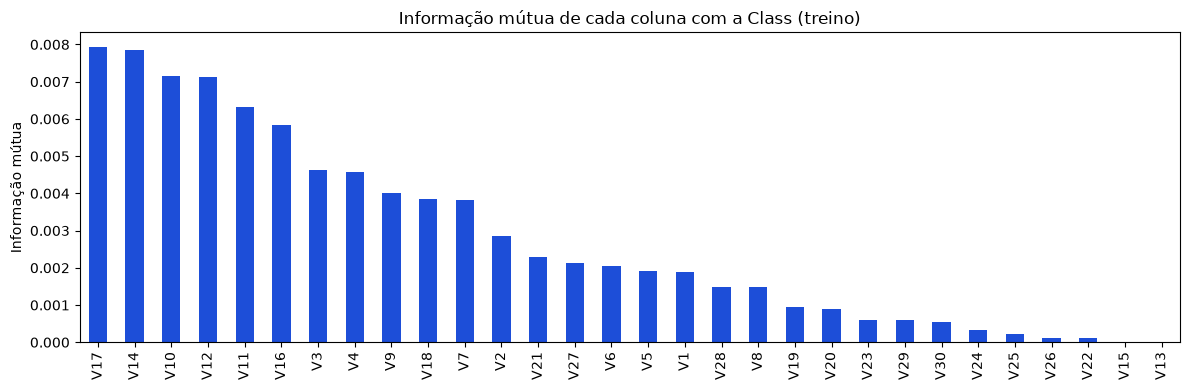

,info_mutua,corr_abs,pos_mi,pos_corr
V17,0.0079,0.3197,1,1
V14,0.0079,0.2987,2,2
V10,0.0071,0.2080,3,4
V12,0.0071,0.2507,4,3
V11,0.0063,0.1507,5,8
V16,0.0058,0.1871,6,6
V3,0.0046,0.1890,7,5
V4,0.0046,0.1269,8,9
V9,0.0040,0.0930,9,13
V18,0.0039,0.1050,10,10


In [4]:
from sklearn.feature_selection import mutual_info_classif
import matplotlib.pyplot as plt

mi = mutual_info_classif(X_treino_p, y_treino, random_state=RANDOM_STATE)
corr = X_treino_p.corrwith(y_treino).abs()

ranking = pd.DataFrame({"info_mutua": mi, "corr_abs": corr}, index=X_treino_p.columns)
ranking["pos_mi"] = ranking["info_mutua"].rank(ascending=False).astype(int)
ranking["pos_corr"] = ranking["corr_abs"].rank(ascending=False).astype(int)
ranking = ranking.sort_values("pos_mi")

ax = ranking["info_mutua"].plot(kind="bar", figsize=(12, 4), color="#1D4ED8")
ax.set_title("Informação mútua de cada coluna com a Class (treino)")
ax.set_ylabel("Informação mútua")
plt.tight_layout()
plt.savefig("../resultados/ranking_info_mutua.png", dpi=150)
plt.show()

ranking.round(4)

In [5]:
import time
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score

CONTAMINACAO = y_treino.mean()

normais = X_treino_p[y_treino == 0]
amostra_normais = normais.sample(n=50_000, random_state=RANDOM_STATE)

top_mi = list(ranking.sort_values("pos_mi").index)
top_corr = list(ranking.sort_values("pos_corr").index)

experimentos = {
    "Sem seleção": top_mi,
    "MI-5": top_mi[:5],
    "MI-10": top_mi[:10],
    "MI-15": top_mi[:15],
    "MI-20": top_mi[:20],
    "Corr-10": top_corr[:10],
    "Corr-15": top_corr[:15],
}

def criar_modelos():
    return {
        "Isolation Forest": IsolationForest(n_estimators=100, contamination=CONTAMINACAO,
                                            random_state=RANDOM_STATE, n_jobs=-1),
        "LOF": LocalOutlierFactor(n_neighbors=20, novelty=True,
                                  contamination=CONTAMINACAO, n_jobs=-1),
    }

linhas = []
for nome_exp, colunas in experimentos.items():
    for nome_modelo, modelo in criar_modelos().items():
        inicio = time.time()
        modelo.fit(amostra_normais[colunas])
        y_pred = (modelo.predict(X_val_p[colunas]) == -1).astype(int)
        score = -modelo.score_samples(X_val_p[colunas])
        linhas.append({
            "experimento": nome_exp, "k": len(colunas), "modelo": nome_modelo,
            "precision": precision_score(y_val, y_pred, zero_division=0),
            "recall": recall_score(y_val, y_pred),
            "f1": f1_score(y_val, y_pred),
            "auprc": average_precision_score(y_val, score),
            "segundos": round(time.time() - inicio, 1),
        })
        print(f"{nome_exp} | {nome_modelo}: ok")

resultados = pd.DataFrame(linhas)
resultados.to_csv("../resultados/comparacao_validacao.csv", index=False)
resultados.round(3)

Sem seleção | Isolation Forest: ok


/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Sem seleção | LOF: ok
MI-5 | Isolation Forest: ok


/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


MI-5 | LOF: ok
MI-10 | Isolation Forest: ok


/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


... (6 outputs left out)

Corr-10 | LOF: ok
Corr-15 | Isolation Forest: ok


/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Corr-15 | LOF: ok


,experimento,k,modelo,precision,recall,f1,auprc,segundos
0,Sem seleção,30,Isolation Forest,0.232,0.245,0.238,0.144,0.4
1,Sem seleção,30,LOF,0.328,0.404,0.362,0.274,2.8
2,MI-5,5,Isolation Forest,0.473,0.851,0.608,0.677,0.5
3,MI-5,5,LOF,0.008,0.011,0.009,0.142,0.7
4,MI-10,10,Isolation Forest,0.455,0.851,0.593,0.675,0.4
5,MI-10,10,LOF,0.000,0.000,0.000,0.083,2.3
6,MI-15,15,Isolation Forest,0.406,0.553,0.468,0.423,0.4
7,MI-15,15,LOF,0.011,0.011,0.011,0.089,9.3
8,MI-20,20,Isolation Forest,0.285,0.394,0.330,0.321,0.4
9,MI-20,20,LOF,0.052,0.053,0.052,0.105,2.4


In [6]:
linhas_lof = []
for nome_exp, colunas in experimentos.items():
    treino_lof = amostra_normais[colunas].drop_duplicates()
    for vizinhos in [20, 50, 100]:
        inicio = time.time()
        modelo = LocalOutlierFactor(n_neighbors=vizinhos, novelty=True,
                                    contamination=CONTAMINACAO, n_jobs=-1)
        modelo.fit(treino_lof)
        y_pred = (modelo.predict(X_val_p[colunas]) == -1).astype(int)
        score = -modelo.score_samples(X_val_p[colunas])
        linhas_lof.append({
            "experimento": nome_exp, "k": len(colunas), "vizinhos": vizinhos,
            "linhas_treino": len(treino_lof),
            "precision": precision_score(y_val, y_pred, zero_division=0),
            "recall": recall_score(y_val, y_pred),
            "f1": f1_score(y_val, y_pred),
            "auprc": average_precision_score(y_val, score),
            "segundos": round(time.time() - inicio, 1),
        })
        print(f"{nome_exp} | {vizinhos} vizinhos: ok")

lof = pd.DataFrame(linhas_lof)
lof.to_csv("../resultados/lof_ajuste_vizinhos.csv", index=False)
lof.pivot(index="experimento", columns="vizinhos", values="auprc").round(3)

/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Sem seleção | 20 vizinhos: ok


/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Sem seleção | 50 vizinhos: ok


/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Sem seleção | 100 vizinhos: ok


... (33 outputs left out)

Corr-15 | 50 vizinhos: ok


/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Corr-15 | 100 vizinhos: ok


vizinhos,20,50,100
experimento,,,
Corr-10,0.243,0.702,0.718
Corr-15,0.314,0.703,0.724
MI-10,0.158,0.754,0.747
MI-15,0.225,0.686,0.702
MI-20,0.304,0.700,0.700
MI-5,0.559,0.740,0.744
Sem seleção,0.274,0.642,0.619


In [7]:
linhas_if = []
for nome_exp, colunas in experimentos.items():
    for arvores in [50, 100, 200, 500]:
        inicio = time.time()
        modelo = IsolationForest(n_estimators=arvores, contamination=CONTAMINACAO,
                                 random_state=RANDOM_STATE, n_jobs=-1)
        modelo.fit(amostra_normais[colunas])
        y_pred = (modelo.predict(X_val_p[colunas]) == -1).astype(int)
        score = -modelo.score_samples(X_val_p[colunas])
        linhas_if.append({
            "experimento": nome_exp, "k": len(colunas), "arvores": arvores,
            "precision": precision_score(y_val, y_pred, zero_division=0),
            "recall": recall_score(y_val, y_pred),
            "f1": f1_score(y_val, y_pred),
            "auprc": average_precision_score(y_val, score),
            "segundos": round(time.time() - inicio, 1),
        })

iso = pd.DataFrame(linhas_if)
iso.to_csv("../resultados/if_ajuste_arvores.csv", index=False)
iso.pivot(index="experimento", columns="arvores", values="auprc").round(3)

arvores,50,100,200,500
experimento,,,,
Corr-10,0.583,0.699,0.661,0.650
Corr-15,0.425,0.429,0.390,0.388
MI-10,0.482,0.675,0.662,0.662
MI-15,0.327,0.423,0.448,0.442
MI-20,0.255,0.321,0.330,0.324
MI-5,0.546,0.677,0.678,0.656
Sem seleção,0.165,0.144,0.147,0.132


In [8]:
from sklearn.metrics import (confusion_matrix, jaccard_score, accuracy_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

finalistas = {
    "Isolation Forest (MI-10, 200 árvores)": (
        IsolationForest(n_estimators=200, contamination=CONTAMINACAO,
                        random_state=RANDOM_STATE, n_jobs=-1),
        experimentos["MI-10"], False),
    "LOF (MI-5, 50 vizinhos)": (
        LocalOutlierFactor(n_neighbors=50, novelty=True,
                           contamination=CONTAMINACAO, n_jobs=-1),
        experimentos["MI-5"], True),
}

linhas_final, scores_final, preds_final = [], {}, {}
for nome, (modelo, colunas, sem_duplicados) in finalistas.items():
    treino = amostra_normais[colunas]
    if sem_duplicados:
        treino = treino.drop_duplicates()
    modelo.fit(treino)
    y_pred = (modelo.predict(X_apres_p[colunas]) == -1).astype(int)
    score = -modelo.score_samples(X_apres_p[colunas])
    scores_final[nome], preds_final[nome] = score, y_pred
    linhas_final.append({
        "modelo": nome,
        "acuracia": accuracy_score(y_apres, y_pred),
        "precision": precision_score(y_apres, y_pred, zero_division=0),
        "recall": recall_score(y_apres, y_pred),
        "f1": f1_score(y_apres, y_pred),
        "jaccard": jaccard_score(y_apres, y_pred),
        "auprc": average_precision_score(y_apres, score),
        "roc_auc": roc_auc_score(y_apres, score),
    })

final = pd.DataFrame(linhas_final)
final.to_csv("../resultados/avaliacao_final_apresentacao.csv", index=False)
final.round(3)

/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
/Users/eduardosanvido/Projetos/Projeto-Fraude/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


,modelo,acuracia,precision,recall,f1,jaccard,auprc,roc_auc
0,"Isolation Forest (MI-10, 200 árvores)",0.997,0.377,0.758,0.503,0.336,0.519,0.937
1,"LOF (MI-5, 50 vizinhos)",0.998,0.468,0.768,0.582,0.410,0.665,0.930


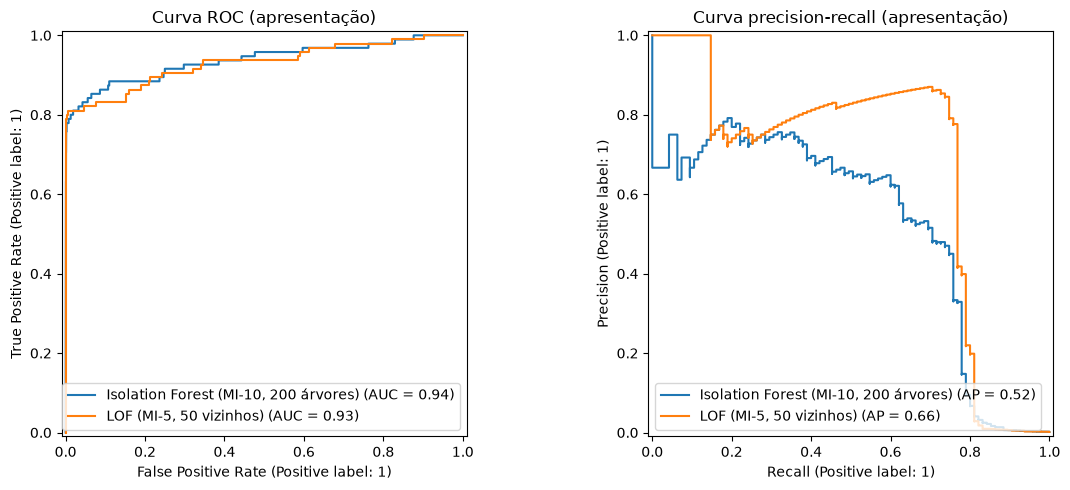

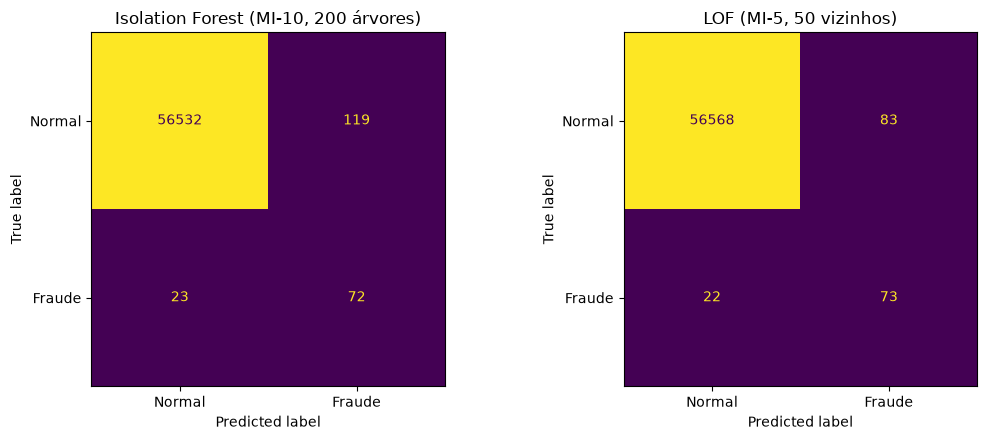

In [9]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))
for nome, score in scores_final.items():
    RocCurveDisplay.from_predictions(y_apres, score, name=nome, ax=eixos[0])
    PrecisionRecallDisplay.from_predictions(y_apres, score, name=nome, ax=eixos[1])
eixos[0].set_title("Curva ROC (apresentação)")
eixos[1].set_title("Curva precision-recall (apresentação)")
plt.tight_layout()
plt.savefig("../resultados/curvas_finais.png", dpi=150)
plt.show()

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))
for eixo, (nome, y_pred) in zip(eixos, preds_final.items()):
    ConfusionMatrixDisplay.from_predictions(y_apres, y_pred, display_labels=["Normal", "Fraude"],
                                            ax=eixo, colorbar=False)
    eixo.set_title(nome)
plt.tight_layout()
plt.savefig("../resultados/matrizes_confusao.png", dpi=150)
plt.show()